<div style="display: flex; align-items: center;">
    <h1>Calibrating phenology parameters on a multi-site dataset with <code>diffWOFOST</code></h1>
    <img src="https://raw.githubusercontent.com/WUR-AI/diffWOFOST/refs/heads/main/docs/logo/diffwofost.png" width="150" style="margin-left: 20px;">
</div>


This notebook extends the single-site example of `optimization_phenology.ipynb` to
many sites at the same time. There the parameters of one site were optimized
against its daily `DVS` trajectory, with one model run per optimizer step. Here
the model parameters are tensors with one value per site, so one engine call
simulates all 600 sites, each from its own start date, and one optimizer step
moves the parameters of all 5 groups together. The observations are the anthesis
and maturity dates of a site, which is what a multi-site dataset of dates
constrains; a daily `DVS` trajectory is not identifiable against measured data.

This Jupyter notebook demonstrates the calibration of parameters in a
differentiable crop model using the `diffwofost` package. The package provides
differentiable implementations of the WOFOST model and its associated
sub-models; this notebook uses the `phenology` sub-model.

The parameters to calibrate are `TSUM1`, the temperature sum from emergence to
anthesis, and `TSUM2`, the temperature sum from anthesis to maturity. The
observations are anthesis and maturity dates at 600 sites, which are divided into
5 groups, each with one pair of temperature sums. The calibration will be done
using the Adam optimizer from `torch.optim`.

The dates are produced by the model itself, with parameters that the optimizer is
not told, so that the calibrated values can be compared with a known answer.

## 1. The batched engine

In this section we describe the parts of the engine that make a calibration on
many sites possible. `diffWOFOST` simulates a batch of elements in one engine run
when the model parameters are tensors with one value per element:

- `Engine(Configuration(...))` can be set up again for every run, so one instance
  serves every optimizer step;
- `CROP_START_DATE` takes one date per element, so the sites of a batch start on
  different days. An element that has not started yet reports NaN, and an element
  that has reached maturity keeps its final `DVS`;
- `to_weather_data_iterator` turns a `(time, site)` dataset into a daily stream of
  tensors, on the device and dtype of `ComputeConfig`;
- `OUTPUT_VARS` exports the daily state variables of every element as tensors, so
  the `DVS` of every site on every day of the calendar can be read after the run.

The last point is what the calibration needs: the gradient of the dates with
respect to the parameters passes through the daily `DVS`.

## 1.1 Software requirements

To run this notebook, we need to install `diffwofost`, the differentiable version
of the WOFOST models. The cell below installs it, and is only needed on a machine
where the package is not installed yet.

The only input of the notebook is one phenology test file of PCSE, which is
downloaded in the next section.


In [1]:
# install diffwofost
%pip install diffwofost



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# ---- import libraries ----
import time
import urllib.request
from contextlib import contextmanager

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr
import yaml
from diffwofost.physical_models.config import ComputeConfig, Configuration
from diffwofost.physical_models.crop.phenology import DVS_Phenology
from diffwofost.physical_models.engine import Engine
from diffwofost.physical_models.weather import to_weather_data_iterator

print('torch', torch.__version__, 'dtype', ComputeConfig.get_dtype(), 'device', ComputeConfig.get_device())


@contextmanager
def timed(step):
    '''Prints how long the enclosed step took.'''
    start = time.perf_counter()
    yield
    print(f'{step}: {time.perf_counter() - start:.1f} s')

torch 2.9.0+cu128 dtype torch.float32 device cpu


## 1.2 Data

A test dataset of phenology will be used to calibrate the parameters:

- `TSUM1`: temperature sum from emergence to anthesis,
- `TSUM2`: temperature sum from anthesis to maturity.

The data is stored in the tests folder of PCSE, in files that follow the pattern
`test_phenology_wofost72_*.yaml`. Each file holds the weather, the crop
parameters and a reference simulation for one location and one crop type. We use
`test_phenology_wofost72_17.yaml`, a winter wheat with a vernalisation requirement
at 48.1 N 7.9 E, for one season from autumn 2010 to summer 2011:

- `WeatherVariables`: the daily weather, of which the phenology model reads
  `TEMP` and `LAT`;
- `ModelParameters`: the crop parameters, with `TSUM1` = 950 and `TSUM2` = 991
  degree-days, the temperature response of development `DTSMTB`, and the
  vernalisation requirements.

The third part of the file, `ModelResults`, is the reference simulation of PCSE
and is not used here.

These parameters describe one site and one crop. To calibrate on a larger
dataset, we read the weather once and build 600 sites from it, in 5 groups with
one pair of temperature sums each: 10 parameters to calibrate.

In [3]:
# ---- one phenology test file of PCSE: the weather and the crop parameters ----
filename = 'test_phenology_wofost72_17.yaml'
url = f'https://raw.githubusercontent.com/ajwdewit/pcse/refs/heads/master/tests/test_data/{filename}'
urllib.request.urlretrieve(url, filename)

with open(filename) as f:
    test_data = yaml.safe_load(f)

weather = pd.DataFrame(test_data['WeatherVariables'])
crop_parameters = test_data['ModelParameters']

first_day = pd.to_datetime(weather.DAY.min())
last_day = pd.to_datetime(weather.DAY.max())
print(f'{len(weather)} days of weather, {first_day.date()} to {last_day.date()}')
print(f'latitude {float(weather.LAT.iloc[0]):.2f}')
print()
for name in ('TSUMEM', 'TBASEM', 'TEFFMX', 'TSUM1', 'TSUM2', 'IDSL', 'DVSEND', 'VERNSAT'):
    if name in crop_parameters:
        print(f'  {name:8s} {crop_parameters[name]}')

279 days of weather, 2010-10-19 to 2011-07-24
latitude 48.11

  TSUMEM   110.0
  TBASEM   0.0
  TEFFMX   30.0
  TSUM1    950.0
  TSUM2    991.0
  IDSL     2.0
  DVSEND   2.0
  VERNSAT  64.0


## 1.3 The sites

In this section we build a dataset of 600 sites from the weather of the test
file. A batch is simulated on one calendar with one weather series per element,
so the sites have to differ in something that the model reads.

The 600 sites are drawn at random in three ways:

- `group`, one of 5, which fixes the `TSUM1` and `TSUM2` of the site; a group
  plays the role of an agro-ecological zone, a set of sites that share one pair
  of temperature sums;
- `offset`, a temperature offset between -2 and +2 °C, so that two sites of the
  same group do not see the same weather;
- `start`, a crop start within the first 15 days.

The season of the test file covers one crop cycle of a winter wheat, while the
sites have to start on different days. The season is therefore repeated once,
which gives a calendar long enough that the latest start still reaches maturity
inside it.

The result is a weather dataset of shape (days, sites), with one temperature
series per site, and one start date per site. `TEMP` is the only weather variable
that the phenology model reads; `LAT` is needed for the day length. `LAT` is a
(days, sites) variable as well, constant in time, because
`to_weather_data_iterator` transposes every weather variable it finds on the time
dimension: a `LAT` coordinate with only a `site` dimension raises
`ValueError: Dimensions {'time'} do not exist`.


In [4]:
# ---- size of the demonstration dataset ----
N_SITES = 600
N_GROUPS = 5
N_SEASONS = 2
START_WINDOW_DAYS = 15
SEED = 42

# ---- one daily temperature series per site: the season of the test file, repeated ----
season = pd.date_range(first_day, last_day, freq='D')
temp_season = (
    pd.Series(weather.TEMP.to_numpy(dtype=float), index=pd.to_datetime(weather.DAY))
    .reindex(season)
    .interpolate()
    .to_numpy()
)
days = pd.date_range(first_day, periods=N_SEASONS * len(season), freq='D')
temp = np.tile(temp_season, N_SEASONS)
lat = float(weather.LAT.iloc[0])

rng = np.random.default_rng(SEED)
group = rng.integers(0, N_GROUPS, N_SITES)
offset = rng.uniform(-2.0, 2.0, N_SITES)
start = rng.integers(0, START_WINDOW_DAYS, N_SITES)

# ---- (time, site) weather: every variable has the time dimension, LAT is constant ----
site_weather = xr.Dataset(
    {
        'TEMP': (('time', 'site'), temp[:, None] + offset[None, :]),
        'LAT': (('time', 'site'), np.full((len(days), N_SITES), lat)),
    },
    coords={'DAY': ('time', days)},
)
start_days = np.array([day.toordinal() for day in days[start]])

print(f'{N_SITES} sites in {N_GROUPS} groups, calendar of {len(days)} days')
print('sites per group    ', np.bincount(group, minlength=N_GROUPS).tolist())
print(f'temperature offset {offset.min():.1f} to {offset.max():.1f} degC')
print(f'crop starts        {days[start].min().date()} to {days[start].max().date()}')


600 sites in 5 groups, calendar of 558 days
sites per group     [129, 104, 129, 117, 121]
temperature offset -2.0 to 2.0 degC
crop starts        2010-10-19 to 2010-11-02


## 2. From a `DVS` trajectory to a differentiable date

The loss of the calibration is a residual in days, so we need the derivative of a
date with respect to `TSUM1` and `TSUM2`. Two details of the `phenology` model
stand in the way.

1. The dates of the model are integers. `phenology.integrate` sets
   `DOA = day_ordinal` when `DVS` reaches 1 and `DOM = day_ordinal` when it
   reaches `DVSEND` = 2, and `day_ordinal` is the calendar day, not a function of
   the parameters. `get_terminal_output()` therefore has no gradient, and a loss
   built on it cannot be backpropagated.
2. On the day of the event itself `DVS` is clamped to exactly the target:
   `s.DVS = where(should_flower, clamp(s.DVS, max=1.0), s.DVS)`. The overshoot of
   that day is discarded, so the value of the event day does not say how far the
   parameters are from the event.

The differentiable output is the daily `DVS` tensor that `OUTPUT_VARS=['DVS']`
saves at every step. We take the event day as the first day with `DVS` at or
above the target, and estimate the sub-day position of the crossing from the day
before the event and from the development rate of the days before that:

$$\hat d = (i-1) + \frac{v - \mathrm{DVS}_{i-1}}{r}, \qquad
r = \frac{\mathrm{DVS}_{i-1} - \mathrm{DVS}_{i-1-w}}{w}, \qquad
v = 1 \text{ for anthesis, } 2 \text{ for maturity},$$

with a window of $w = 10$ days. A window and not a single day, because `DVS` does
not advance on days below the base temperature. At the starting parameters of
section 4 one site sits at $DVS = 1.997$ for 12 days of temperatures between
$-9.6$ and $0\,°C$ before it crosses maturity. The increment of a single day is
zero over that spell, and dividing by it placed the maturity of that site three
thousand days after the observation, which is large enough to make the loss of the
whole batch bounce between 10 and 123 days from one optimizer step to the next.
The rate is also floored at $5\cdot 10^{-3}$ per day, which bounds the
extrapolation of the next paragraph.

The rate in the denominator is detached, so the gradient is

$$\frac{\partial \hat d}{\partial \theta} = -\frac{\partial \mathrm{DVS}_{i-1}/\partial \theta}{r},$$

the implicit derivative of the crossing condition with the local development rate
held fixed: the shift of the crossing day, in days, per unit of the parameter. The
floor on $r$ keeps that gradient finite. The value of $\hat d$ stays near the
integer crossing day: at the starting parameters of section 4 the two differ by
between $-1.0$ and $+1.0$ day, with a mean absolute difference of $0.46$ day for
anthesis and $0.55$ day for maturity. The metrics in section 5 use the integer
dates of the engine, so that this convention does not enter them.

When a target is not reached before the end of the calendar, we extrapolate the
same expression from the last day. Without it an observation that the model cannot
reach would drop out of the loss, and the optimizer would be free to overshoot
`TSUM2`.


In [5]:
# ---- parameter ranges and optimizer settings ----
TSUM1_MIN, TSUM1_MAX = 0.0, 1500.0
TSUM2_MIN, TSUM2_MAX = 0.0, 1500.0
MAX_STEPS = 150
PATIENCE = 25
LEARNING_RATE = 0.02
EVENT_TARGETS = {'DOA': 1.0, 'DOM': 2.0}   # DVS value that marks the event
DATE_WEIGHTS = {'DOA': 0.5, 'DOM': 0.5}
RATE_WINDOW_DAYS = 10                      # days over which the DVS rate is measured
MIN_RATE = 5e-3                            # floor of that rate, in DVS per day


# ---- parameters kept inside [low, high] through a logit, one value per element of the init ----
class BoundedParameters(torch.nn.Module):
    def __init__(self, low, high, init_values):
        super().__init__()
        self.low = low
        self.high = high
        init = torch.as_tensor(init_values, dtype=ComputeConfig.get_dtype())
        self.raw = torch.nn.Parameter(torch.logit((init - low) / (high - low), eps=1e-6))

    def forward(self):
        return self.low + (self.high - self.low) * torch.sigmoid(self.raw)


def event_days(dvs, target, window=RATE_WINDOW_DAYS, min_rate=MIN_RATE):
    '''Day index of the first day on which DVS reaches target, as a differentiable float.

    dvs      : (n_days, n_obs) DVS of one batched run, NaN before the crop start of an element
    target   : 1.0 for anthesis, 2.0 for maturity
    window   : number of days over which the development rate is measured
    min_rate : lower bound of that rate, in DVS per day

    The event day is the first day with DVS >= target. On that day phenology.integrate
    clamps DVS to exactly target, so the value of that day carries no gradient. The
    sub-day position of the crossing is therefore estimated from the day before the event
    and from the development rate of the days before that:

        day  = i - 1 + (target - DVS[i-1]) / rate
        rate = (DVS[i-1] - DVS[i-1-window]) / window

    The rate is averaged over a window because the increment of a single day can be zero:
    DVS does not advance on days below the base temperature, and a site that reaches
    maturity at the end of such a spell would otherwise divide by zero and place its
    maturity centuries away. The rate is detached, so the gradient is the implicit
    derivative of the crossing condition, dDVS[i-1]/dtheta divided by the rate: the shift
    of the crossing day, in days, per unit of theta. Its lower bound keeps that gradient
    finite.

    When target is not reached before the end of the calendar, the same expression is
    extrapolated from the last day, so the observation still contributes to the loss.

    Returns day (n_obs,), first (n_obs, index of the first crossing day) and reached
    (n_obs, bool).
    '''
    n_days = dvs.shape[0]
    reached = dvs >= target                                       # NaN compares as False
    first = ((reached.to(torch.int32).cumsum(dim=0)) == 0).sum(dim=0)
    reached_any = first < n_days
    index = torch.where(
        reached_any, (first - 1).clamp(min=0), torch.full_like(first, n_days - 1)
    )
    start = (index - window).clamp(min=0)
    value = torch.nan_to_num(torch.gather(dvs, 0, index.unsqueeze(0)).squeeze(0), nan=0.0)
    earlier = torch.nan_to_num(torch.gather(dvs, 0, start.unsqueeze(0)).squeeze(0), nan=0.0)
    span = (index - start).to(dvs.dtype).clamp(min=1.0)
    rate = ((value - earlier) / span).detach().clamp(min=min_rate)
    day = index.to(dvs.dtype) + (target - value) / rate
    return day, first, reached_any


## 2.1 One model for all sites

We wrap the engine in a class called `GroupPhenology`, a subclass of
`torch.nn.Module`, to make it easy to run the model with the current parameters.
The class holds one `TSUM1` and one `TSUM2` per group as logits and turns them
into one value per site with a group index at every forward pass. The engine then
receives a tensor of 600 temperature sums and simulates the 600 sites at once,
each from its own start date.

The weather is built once and reused. A forward pass re-runs the engine from the
first day of the calendar, so every optimizer step recomputes the whole
trajectory. From the trajectory the model keeps four numbers per site: the day of
anthesis, the day of maturity, and whether each of the two was reached.

In [6]:
def as_vector(values, n):
    '''One value per group, whether a single value or one value per group was given.'''
    return np.broadcast_to(np.asarray(values, dtype=float), (n,)).copy()


def simulate_batch(parameters, weather, tsum1, tsum2, start_days, engine):
    '''One batched diffWOFOST run over all sites.

    parameters : crop parameters of the test file
    weather    : (time, site) dataset, one lane per site
    tsum1      : tensor with one value per site
    tsum2      : tensor with one value per site
    start_days : crop start of each site, as a date ordinal

    Returns dvs (n_days, n_sites), the calendar ordinals (n_days,) and the terminal output
    of the engine, DOA and DOM as date ordinals with -1 for an event that did not occur.
    '''
    calendar = pd.to_datetime(weather.DAY.values)
    engine.setup(
        dict(parameters) | {
            'TSUM1': tsum1,
            'TSUM2': tsum2,
            'CROP_START_TYPE': 'sowing',
            'CROP_END_TYPE': 'maturity',
            'CROP_START_DATE': start_days,
        },
        to_weather_data_iterator(weather),
        [{calendar[0].date(): None}, {calendar[-1].date(): None}],
    )
    engine.run_till_terminate()
    output = engine.get_output()
    dvs = torch.stack([row['DVS'] for row in output])
    ordinals = np.array([row['day'].toordinal() for row in output])
    terminal = {var: value.detach().clone() for var, value in engine.get_terminal_output().items()}
    del output
    return dvs, ordinals, terminal


class GroupPhenology(torch.nn.Module):
    '''One TSUM1/TSUM2 pair per group of sites, fitted on all sites of the batch.'''

    def __init__(self, parameters, weather, group, start_days, tsum1_init, tsum2_init, engine):
        super().__init__()
        # not self.parameters: that name is the method of torch.nn.Module
        self.crop_parameters = parameters
        self.weather = weather
        self.group = torch.as_tensor(group, dtype=torch.long)
        self.start_days = start_days
        self.engine = engine
        n_groups = int(self.group.max()) + 1
        self.TSUM1 = BoundedParameters(TSUM1_MIN, TSUM1_MAX, as_vector(tsum1_init, n_groups))
        self.TSUM2 = BoundedParameters(TSUM2_MIN, TSUM2_MAX, as_vector(tsum2_init, n_groups))

    def forward(self):
        dvs, ordinals, terminal = simulate_batch(
            self.crop_parameters,
            self.weather,
            self.TSUM1()[self.group],
            self.TSUM2()[self.group],
            self.start_days,
            self.engine,
        )
        prediction = {
            'calendar': ordinals,
            'dvs': dvs,
            'terminal': terminal,
            'pred': {},
            'first': {},
            'reached': {},
        }
        for var, target in EVENT_TARGETS.items():
            day_index, first, reached_any = event_days(dvs, target)
            # the calendar is daily, so ordinal = ordinal of the first row + day index
            prediction['pred'][var] = float(ordinals[0]) + day_index.to(torch.float64)
            prediction['first'][var] = first
            prediction['reached'][var] = reached_any
        return prediction

## 3. Loss and optimizer

The residual of a site is a difference of dates, in days. We use the mean of the
two RMSEs as loss, one per date type:

$$L = \frac{w_{DOA}\,\mathrm{RMSE}_{DOA} + w_{DOM}\,\mathrm{RMSE}_{DOM}}{w_{DOA} + w_{DOM}}, \qquad w = 0.5 \text{ each}.$$

The weights are equal so that neither date type dominates the loss through the
number of observations behind it. A site whose event falls outside the calendar
leaves the RMSE of that date type.

The class `BoundedParameters` keeps the parameters inside `[0, 1500]` degree-days
by mapping them through a logit. The optimization will be done using the Adam
optimizer from `torch.optim`, which works on the logit: a step of `lr` moves a
parameter by `(high - low) * sigmoid'(raw) * lr` degree-days, and a range that is
too narrow would also shrink the step and stall the optimization.

In [7]:
def residuals(prediction, observed, var, use_terminal=False):
    '''Predicted and observed date ordinals of one date type, for the sites where both exist.'''
    if use_terminal:
        pred = prediction['terminal'][var].to(torch.float64)
        mask = pred > 0                     # -1 marks an event that the engine did not reach
    else:
        pred = prediction['pred'][var]
        mask = torch.isfinite(pred)
    obs = observed[var]
    mask = mask & ~torch.isnan(obs)
    return pred[mask], obs[mask]


def loss_fn(prediction, observed, weights=DATE_WEIGHTS):
    '''Weighted mean of the RMSE in days of anthesis and of maturity.'''
    total, weight_sum, terms = 0.0, 0.0, {}
    for var, weight in weights.items():
        pred, obs = residuals(prediction, observed, var)
        if pred.numel():
            terms[var] = torch.sqrt(((pred - obs) ** 2).mean())
            total = total + weight * terms[var]
            weight_sum += weight
    if not terms:
        raise ValueError('No observed date, nothing to calibrate')
    return total / weight_sum, terms


def date_metrics(prediction, observed):
    '''RMSE, bias and MAE in days per date type, from the engine own integer dates.'''
    rows = []
    for var in EVENT_TARGETS:
        pred, obs = residuals(prediction, observed, var, use_terminal=True)
        if pred.numel():
            d = pred - obs
            rows.append({
                'date': var,
                'n': d.numel(),
                'bias': d.mean().item(),
                'rmse': d.pow(2).mean().sqrt().item(),
                'mae': d.abs().mean().item(),
            })
    return pd.DataFrame(rows).set_index('date')


def metric(table, var, column):
    '''One cell of date_metrics, NaN when the group has no observation of that date.'''
    if var in table.index:
        return float(table.loc[var, column])
    return float('nan')


def _term(terms, var):
    '''Format one RMSE term, or n/a when the date type has no observation.'''
    return f'{terms[var].item():.2f}' if var in terms else 'n/a'


def calibrate(model, observed, max_steps=MAX_STEPS, lr=LEARNING_RATE, patience=PATIENCE,
              min_delta=1e-4, verbose=True):
    '''Adam on the two bounded parameters, with early stopping on the training loss.

    Returns the loss after every step. The last entry is the loss of the best parameters,
    which are the ones left in the model, so that a report of history[-1] refers to the
    parameters that are actually returned.
    '''
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss, best_state, waited, history = float('inf'), None, 0, []
    for step in range(max_steps + 1):
        optimizer.zero_grad()
        loss, terms = loss_fn(model(), observed)
        history.append(loss.item())
        if verbose:
            rmse_doa, rmse_dom = _term(terms, 'DOA'), _term(terms, 'DOM')
            print(
                f'Step {step}, loss {loss.item():.3f} days, RMSE DOA {rmse_doa}, '
                f'RMSE DOM {rmse_dom}'
            )
        if step == max_steps:
            break
        # keep the parameters that produced this loss, before the step replaces them
        if loss.item() < best_loss - min_delta:
            best_loss, waited = loss.item(), 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                print(f'Early stopping at step {step}, best loss {best_loss:.3f} days')
                break
        loss.backward()
        optimizer.step()
    if best_state is not None:
        model.load_state_dict(best_state)
        with torch.no_grad():
            final_loss, _ = loss_fn(model(), observed)
        history[-1] = final_loss.item()
    return history


### 3.1 The observed dates

A calibration needs observations. Here the observations are produced by a
reference run with a `TSUM1` and a `TSUM2` per group that the optimizer is not
told, so the exercise is a recovery test: a good fit has to return the parameters
of that reference run. We read the dates from the terminal output of the reference
run, which makes them whole days, as measured dates are.

To use measured dates instead, replace the `observed` dictionary by your own dates
as date ordinals; nothing else changes.

The cell also checks the machinery: the crossing day computed from the `DVS`
trajectory has to be the `DOA` and `DOM` that the engine reports.

In [8]:
# ---- the true parameters of each group, and the reference run they produce ----
tsum1_true = crop_parameters['TSUM1'] * np.array([0.85, 0.95, 1.05, 1.15, 1.25])
tsum2_true = crop_parameters['TSUM2'] * np.array([1.20, 1.10, 1.00, 0.90, 0.80])

engine = Engine(Configuration(
    CROP=DVS_Phenology,
    OUTPUT_VARS=['DVS'],
    TERMINAL_OUTPUT_VARS=['DOA', 'DOM'],
))

truth = GroupPhenology(
    crop_parameters, site_weather, group, start_days, tsum1_true, tsum2_true, engine
)
with torch.no_grad():
    with timed('Reference run with the true parameters'):
        reference = truth()

# the observations are the integer dates of the reference run, NaN where no event occurred
nan = torch.tensor(float('nan'), dtype=torch.float64)
observed = {
    var: torch.where(reference['terminal'][var] > 0,
                     reference['terminal'][var].to(torch.float64), nan)
    for var in EVENT_TARGETS
}

for var in EVENT_TARGETS:
    crossing = float(reference['calendar'][0]) + reference['first'][var].to(torch.float64)
    engine_day = reference['terminal'][var].to(torch.float64)
    mask = engine_day > 0
    assert torch.equal(crossing[mask], engine_day[mask]), var
    print(f'{var}: {int(mask.sum())} of {N_SITES} sites reached the event, '
          f'crossing day of the DVS trajectory matches the engine date on all of them')

Reference run with the true parameters: 1.8 s
DOA: 600 of 600 sites reached the event, crossing day of the DVS trajectory matches the engine date on all of them
DOM: 600 of 600 sites reached the event, crossing day of the DVS trajectory matches the engine date on all of them


### 3.2 The trajectories the dates come from

The figure shows the daily `DVS` of one site per group in the reference run. The two
dashed lines are the thresholds of anthesis (`DVS` = 1) and maturity (`DVS` = 2); the
markers are the crossing days that `event_days` computes from the day before the
crossing and from the development rate of the 10 days before that. Those markers are
the dates that the loss differentiates. The five sites start on different days, and
the `DVS` of a site that has reached maturity stays at 2, which is the flat part at
the end of each line.

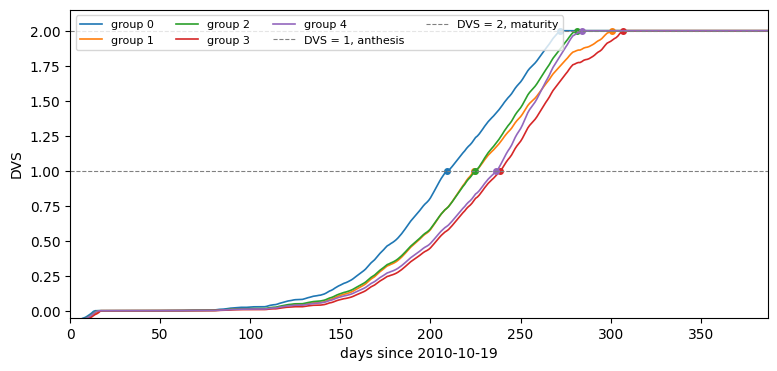

In [9]:
# ---- the DVS trajectory of one site per group, with the crossing days that become the dates ----
sites = [int(np.flatnonzero(group == g)[0]) for g in range(N_GROUPS)]
t = np.arange(len(reference['calendar']))
first_ordinal = reference['calendar'][0]
last_event = max(float(reference['terminal'][var].max()) for var in EVENT_TARGETS) - first_ordinal

fig, ax = plt.subplots(figsize=(9, 4))
for g, site in enumerate(sites):
    ax.plot(t, reference['dvs'][:, site], lw=1.2, label=f'group {g}')
    for var, target in EVENT_TARGETS.items():
        ax.plot(float(reference['pred'][var][site]) - first_ordinal, target, 'o', ms=4, color=f'C{g}')
for target, name in ((1.0, 'anthesis'), (2.0, 'maturity')):
    ax.axhline(target, color='0.5', lw=0.8, ls='--', label=f'DVS = {target:.0f}, {name}')
ax.set_xlim(0, last_event + 20)
ax.set_ylim(-0.05, 2.15)
ax.set_xlabel(f'days since {pd.Timestamp.fromordinal(int(first_ordinal)).date()}')
ax.set_ylabel('DVS')
ax.legend(ncol=4, fontsize=8, loc='upper left')
plt.show()

### 3.3 The cost of one pass

The cell times one forward pass and one backward pass over the 600 sites and
prints the RMSE of the starting parameters. The cost of the calibration is that
time multiplied by the number of optimizer steps.

In [10]:
# ---- the model that will be calibrated, starting from the crop parameters of the file ----
model = GroupPhenology(
    crop_parameters, site_weather, group, start_days,
    crop_parameters['TSUM1'], crop_parameters['TSUM2'], engine,
)

with torch.no_grad():
    with timed('Forward pass without gradients'):
        start_prediction = model()
before = date_metrics(start_prediction, observed)
print(before.round(2).to_string())

with timed('Forward and backward pass with gradients'):
    model.zero_grad()
    loss, terms = loss_fn(model(), observed)
    loss.backward()
print(f'loss {loss.item():.2f} days, sum of |dloss/dTSUM1| over the groups '
      f'{model.TSUM1.raw.grad.abs().sum().item():.3f} per logit unit')

Forward pass without gradients: 1.8 s
        n  bias   rmse   mae
date                        
DOA   600 -2.73   8.27  7.17
DOM   600 -7.24  12.89  7.24
Forward and backward pass with gradients: 2.1 s
loss 10.83 days, sum of |dloss/dTSUM1| over the groups 8.830 per logit unit


## 4. Calibration

In this section we run the optimization on the 10 parameters, 2 per group,
starting from the values of the test file. The loop runs at most 150 steps and
stops when the loss has not improved by at least 1e-4 day for 25 steps. The model
keeps the parameters that produced the best loss, not the last ones, so the
figures of section 5 describe those parameters.

The figure after the cell plots the loss of every step. It falls from 10.8 day at
step 0 to 1.42 day at step 47, and it does not decrease monotonically: it rises
again from one step to the next, by up to 0.6 day at step 8.

In [11]:
with timed('Calibration'):
    history = calibrate(model, observed, max_steps=MAX_STEPS, lr=LEARNING_RATE, patience=PATIENCE)

with torch.no_grad():
    final_prediction = model()
after = date_metrics(final_prediction, observed)
print()
print(f'Best loss {history[-1]:.2f} days after {len(history) - 1} steps')
print(after.round(2).to_string())

Step 0, loss 10.834 days, RMSE DOA 8.45, RMSE DOM 13.21
Step 1, loss 9.542 days, RMSE DOA 8.12, RMSE DOM 10.97
Step 2, loss 8.461 days, RMSE DOA 7.79, RMSE DOM 9.13
Step 3, loss 7.755 days, RMSE DOA 7.47, RMSE DOM 8.04
Step 4, loss 7.450 days, RMSE DOA 7.14, RMSE DOM 7.76
Step 5, loss 7.976 days, RMSE DOA 6.83, RMSE DOM 9.13
Step 6, loss 8.171 days, RMSE DOA 6.52, RMSE DOM 9.82
Step 7, loss 8.613 days, RMSE DOA 6.22, RMSE DOM 11.00
Step 8, loss 9.207 days, RMSE DOA 5.93, RMSE DOM 12.48
Step 9, loss 8.959 days, RMSE DOA 5.65, RMSE DOM 12.27
Step 10, loss 9.126 days, RMSE DOA 5.37, RMSE DOM 12.88
Step 11, loss 8.968 days, RMSE DOA 5.10, RMSE DOM 12.83
Step 12, loss 8.806 days, RMSE DOA 4.83, RMSE DOM 12.78
Step 13, loss 8.794 days, RMSE DOA 4.58, RMSE DOM 13.01
Step 14, loss 8.335 days, RMSE DOA 4.32, RMSE DOM 12.35
Step 15, loss 8.248 days, RMSE DOA 4.08, RMSE DOM 12.42
Step 16, loss 7.896 days, RMSE DOA 3.84, RMSE DOM 11.95
Step 17, loss 7.911 days, RMSE DOA 3.61, RMSE DOM 12.21
Step 1

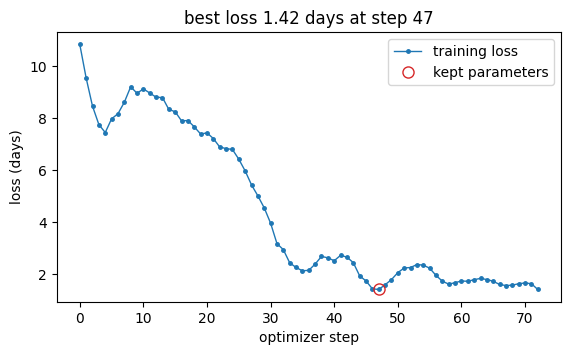

In [12]:
# ---- the loss of every optimizer step, and the step whose parameters were kept ----
best_step = int(np.argmin(history))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(history, '-o', ms=2.5, lw=1, label='training loss')
ax.plot(best_step, history[best_step], 'o', ms=8, mfc='none', color='C3', label='kept parameters')
ax.set_xlabel('optimizer step')
ax.set_ylabel('loss (days)')
ax.set_title(f'best loss {history[best_step]:.2f} days at step {best_step}')
ax.legend()
plt.show()

## 5. What the fit recovered

Finally, we compare the calibrated values with the ones that produced the
observations, and the RMSE in days before and after the calibration. Because the
answer is known, the table and the figure show what the optimizer and the
differentiable date achieve on this problem; on measured dates they would also
contain the error of the model itself.

In [13]:
fitted = pd.DataFrame({
    'sites': np.bincount(group, minlength=N_GROUPS),
    'TSUM1_true': tsum1_true,
    'TSUM1_fitted': model.TSUM1().detach().numpy(),
    'TSUM2_true': tsum2_true,
    'TSUM2_fitted': model.TSUM2().detach().numpy(),
})
fitted['TSUM1_error'] = fitted.TSUM1_fitted - fitted.TSUM1_true
fitted['TSUM2_error'] = fitted.TSUM2_fitted - fitted.TSUM2_true
print(fitted.round(1).to_string())

overall = pd.DataFrame({
    'before': [metric(before, 'DOA', 'rmse'), metric(before, 'DOM', 'rmse')],
    'after': [metric(after, 'DOA', 'rmse'), metric(after, 'DOM', 'rmse')],
}, index=['anthesis (DOA)', 'maturity (DOM)'])
print()
print('RMSE in days over all sites')
print(overall.round(2).to_string())

   sites  TSUM1_true  TSUM1_fitted  TSUM2_true  TSUM2_fitted  TSUM1_error  TSUM2_error
0    129       807.5    810.000000      1189.2   1196.199951          2.5          7.0
1    104       902.5    912.400024      1090.1   1082.199951          9.9         -7.9
2    129       997.5   1005.599976       991.0    986.400024          8.1         -4.6
3    117      1092.5   1095.699951       891.9    887.400024          3.2         -4.5
4    121      1187.5   1209.000000       792.8    768.200012         21.5        -24.6

RMSE in days over all sites
                before  after
anthesis (DOA)    8.27   0.71
maturity (DOM)   12.89   2.33


The figure below compares the two ends of the calibration, the parameters on the
left and the dates in the other two panels.

- **Left panel, the parameters.** Each marker is one group, its fitted temperature
  sum against the value that produced the observations: circles for `TSUM1`,
  squares for `TSUM2`, and the grey dashed line where fitted and true are equal. A
  marker on that line is an exact recovery, and its distance from the line is the
  error in degree-days listed in the `TSUM1_error` and `TSUM2_error` columns of the
  table. Both axes run from 0 so that `TSUM1` and `TSUM2` share one scale; that puts
  the ten values, between 770 and 1210 degree-days, in the upper right corner, and
  the largest error of the table, 24.6 degree-days, at about 2% of the axis length.
- **Middle and right panels, the dates.** The titles name the date type, and each
  bar counts sites with the same residual, simulated minus observed in whole days,
  so a bar left of zero holds sites whose date came too early. The blue step is the
  starting parameters of section 3.3 and the orange step the fitted ones. The blue
  histograms break into blocks a few days apart, one per group, because the sites of
  a group share one pair of temperature sums and with it their error in days: the
  residuals then span more than 25 days for anthesis and more than 60 days for
  maturity. The orange histograms put almost every site within one or two days of
  zero, which is the same result as the RMSE row of the table, 0.71 day for anthesis
  and 2.33 day for maturity.

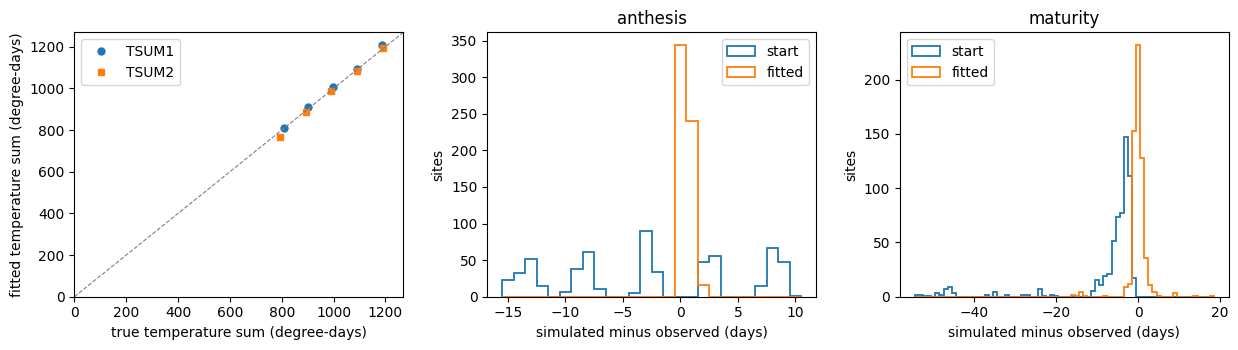

In [14]:
# ---- recovered against true temperature sums, and residuals of every site before and after ----
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))

ax = axes[0]
for parameter, marker in (('TSUM1', 'o'), ('TSUM2', 's')):
    ax.plot(
        fitted[f'{parameter}_true'], fitted[f'{parameter}_fitted'],
        marker, ms=5, label=parameter,
    )
columns = ['TSUM1_true', 'TSUM1_fitted', 'TSUM2_true', 'TSUM2_fitted']
limit = 1.05 * fitted[columns].to_numpy().max()
ax.plot([0.0, limit], [0.0, limit], color='0.5', lw=0.8, ls='--')
ax.set_xlim(0.0, limit)
ax.set_ylim(0.0, limit)
ax.set_xlabel('true temperature sum (degree-days)')
ax.set_ylabel('fitted temperature sum (degree-days)')
ax.legend()

for ax, var, name in zip(axes[1:], EVENT_TARGETS, ('anthesis', 'maturity')):
    differences = {}
    for label, prediction in (('start', start_prediction), ('fitted', final_prediction)):
        pred, obs = residuals(prediction, observed, var, use_terminal=True)
        differences[label] = (pred - obs).numpy()
    bins = np.arange(
        min(d.min() for d in differences.values()) - 0.5,
        max(d.max() for d in differences.values()) + 1.5,
        1.0,
    )
    for label in ('start', 'fitted'):
        ax.hist(differences[label], bins=bins, histtype='step', lw=1.3, label=label)
    ax.set_title(name)
    ax.set_xlabel('simulated minus observed (days)')
    ax.set_ylabel('sites')
    ax.legend()

plt.tight_layout()
plt.show()

## 6. Caveats

- The dates are made by the model, so the errors in section 5 measure the
  optimizer and the differentiable date, not the model. On measured dates the same
  code applies, but nothing guarantees that one `TSUM1` and one `TSUM2` per group
  can explain them.
- `CROP_START_TYPE` is one value per engine run, so a dataset that mixes emergence
  and sowing starts needs one run per start type. The usual rule takes the crop
  start at the observed emergence date where there is one and at sowing otherwise;
  every site here starts at sowing.
- The calendar repeats the season of the test file once, so the last weeks of the
  latest-starting sites are driven by a repeated season and not by a measured one.
- The gradient is exact where the `DVS` trajectory is smooth. It does not include
  the one-day jump of the crossing index when a step pushes an event over a day
  boundary, so the loss is a step-wise approximation of the dependence of a date on
  the parameters. How much that costs is not measured here.
- The rate that turns the `DVS` shortfall of the crossing day into days is the
  mean over the previous 10 days, floored at 5e-3 per day. On a site whose
  development stalls that mean is not the instantaneous rate, so the estimated
  date of the crossing carries an error of a few days; the metrics of section 5
  use the integer dates of the engine and do not contain it.
- All sites of a group share one `TSUM1` and one `TSUM2`; `TSUMEM`, `TBASEM`,
  `TEFFMX`, `IDSL`, `DTSMTB` and the vernalisation parameters stay at the values
  of the test file.
- A pass costs one model step per day of the calendar for every site, and the
  memory for the autograd graph grows with the same product. Splitting the sites
  into batches lowers the memory and leaves the number of steps unchanged. The
  calibration of section 4 takes about 160 s on a laptop CPU.